# Locally Sparse Estimation for Functional Linear Models with Scalar Response (Stefanucci, Bernardi & Canale 2025)

This notebook aims to replicate the simulation from the aforementioned paper, comparing the overlap group lasso against other methods via integrated squared error for the three test functions.

We begin by importing necessary packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
from fdaSP import SBC, SBC_sim

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

The three true coefficient functions are:

- $\psi_1$: zero on $[0.3, 0.7]$;
- $\psi_2$: zero outside $[0.25, 0.75]$;
- $\psi_3$: no null region, control to make sure method doesn't invent sparsity.

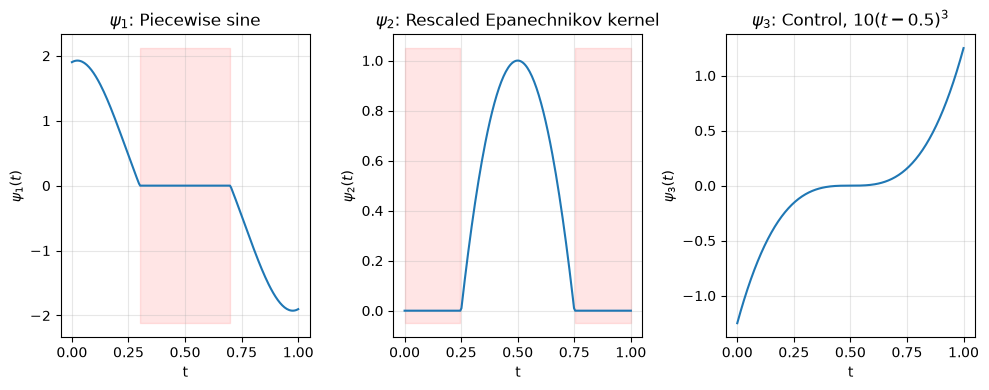

In [2]:
grid = np.linspace(0, 1, 200)
titles = [r"$\psi_1$: Piecewise sine",
          r"$\psi_2$: Rescaled Epanechnikov kernel",
          r"$\psi_3$: Control, $10(t - 0.5)^3$"]

fig, axes = plt.subplots(1, 3)
for i, (ax, (name, (fn, mask_fn)), title) in enumerate(
        zip(axes, SBC_sim.TRUE_FUNCTIONS.items(), titles)):
    ax.plot(grid, fn(grid))
    nm = mask_fn(grid)
    if nm.any():
        ax.fill_between(grid, ax.get_ylim()[0], ax.get_ylim()[1], where=nm,
                        alpha=0.1, color="red")
    ax.set_xlabel("t")
    ax.set_ylabel(fr"$\psi_{i + 1}(t)$")
    ax.set_title(title)
plt.tight_layout()
plt.show()

We are interested in seeing where $\psi$ is exactly zero. `SBC.fit` returns `null_regions` and `support_regions` directly in the result dict.

A problem I ran into when attempting to showcase this feature is that the $\lambda$ that minimises CV error (or its one-SE variant) usually doesn't zero out any regions. Can be understood by the fact that CV is optimising prediction error, not sparsity for the sake of it. We come back to this at the end.

Regardless, to demonstrate the feature, we pick a larger $\lambda$ by hand from the path, with `n_basis=25`.

lambda = 0.05, converged = True
null_regions: [(np.float64(0.3232), np.float64(0.7273))]
true null region: (0.3, 0.7)


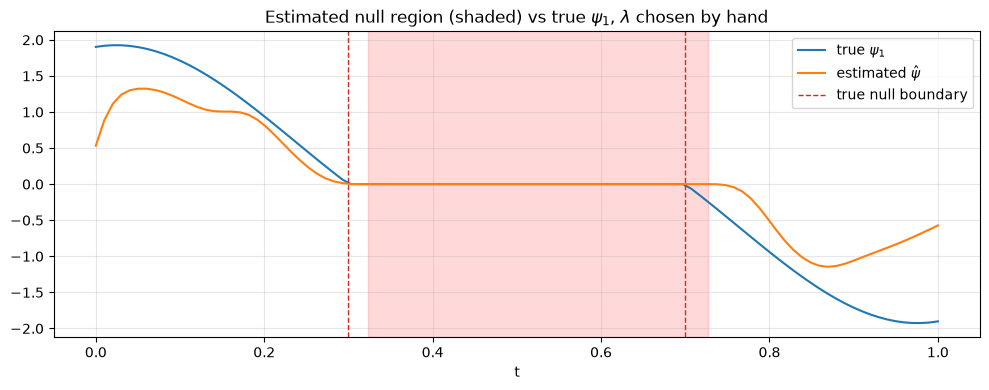

In [3]:
X_demo, y_demo, grid_demo, beta_true_demo = SBC_sim.simulate(SBC_sim.psi1, n=50, m=100)
res_demo = SBC.fit(X_demo, y_demo, grid_demo, lam=0.05, n_basis=25, order=4)
print(f"lambda = {res_demo['lam']:.4g}, converged = {res_demo['converged']}")
print("null_regions:", [(round(a, 4), round(b, 4)) for a, b in res_demo["null_regions"]])
print("true null region: (0.3, 0.7)")

fig, ax = plt.subplots()
ax.plot(grid_demo, beta_true_demo, label=r"true $\psi_1$")
ax.plot(grid_demo, res_demo["beta"], label=r"estimated $\hat\psi$")
for a, b in res_demo["null_regions"]:
    ax.axvspan(a, b, color="red", alpha=0.15)
ax.axvline(0.3, color="C3", ls="--", lw=1)
ax.axvline(0.7, color="C3", ls="--", lw=1, label="true null boundary")
ax.set_xlabel("t")
ax.legend()
ax.set_title(r"Estimated null region (shaded) vs true $\psi_1$, $\lambda$ chosen by hand")
plt.tight_layout()
plt.show()

We can see that the estimated null region is essentially the right width, but displaced to the
right by about half a knot spacing at each end. The boundaries can only fall where a whole
group of four consecutive coefficients switches off at once, so the resolution of the estimated
null set is the knot spacing, not the observation grid.

The paper compares their method against Lasso, Ridge, Elastic Net (using R's `glmnet`; here we use `sklearn`, the estimator is ultimately identical). These four methods all operate on the same functional design matrix $W$, so the only thing varying is the penalty, meaning we can isolate the effect of the OGL penalty.

We also add FPCA as a competitor, not from the paper. Unlike the other four methods, this works directly with the raw curves rather than $W$.

Since $\gamma = 0$ throughout the paper, we set `fit_intercept=False` in the estimators.

For each function and each repetition, we generate a dataset, fit the OGL and the five competitors on the same data, and record the ISE of each one against the true coefficient function: first the overall ISE, then split into the true null region $T_0$ and its complement $T_1$, which the paper computes but does not report.

In [4]:
warnings.filterwarnings("ignore")
results = SBC_sim.run_sim(n_rep=100)
print("done")

psi1: 10/100


psi1: 20/100


psi1: 30/100


psi1: 40/100


psi1: 50/100


...

psi3: 70/100


psi3: 80/100


psi3: 90/100


psi3: 100/100


done


In [5]:
print(f"{'fn':6}{'method':9}{'ISE mean':>10}{'ISE sd':>9}{'ISE_T0':>9}{'ISE_T1':>9}"
      f"{'T0+T1':>9}")
for r in SBC_sim.summarise(results):
    total = r["ise_T0_mean"] + r["ise_T1_mean"] if not np.isnan(r["ise_T0_mean"]) \
        else r["ise_T1_mean"]
    print(
        f"{r['function']:6}{r['method']:9}{r['ise_mean']:10.4f}"
        f"{r['ise_sd']:9.4f}{r['ise_T0_mean']:9.4f}{r['ise_T1_mean']:9.4f}{total:9.4f}"
    )

fn    method     ISE mean   ISE sd   ISE_T0   ISE_T1    T0+T1
psi1  Ogl          0.0907   0.0451   0.0152   0.0755   0.0907
psi1  Lasso        0.1351   0.0542   0.0151   0.1200   0.1351
psi1  Ridge        0.1097   0.0597   0.0220   0.0877   0.1097
psi1  Enet         0.1100   0.0477   0.0181   0.0919   0.1100
psi1  Splines      0.1862   0.0904   0.0428   0.1434   0.1862
psi1  FPCA         0.4416   0.1522   0.0972   0.3444   0.4416
psi2  Ogl          0.0141   0.0090   0.0051   0.0091   0.0141
psi2  Lasso        0.0150   0.0078   0.0027   0.0123   0.0150
psi2  Ridge        0.0186   0.0127   0.0082   0.0104   0.0186
psi2  Enet         0.0146   0.0076   0.0043   0.0104   0.0146
psi2  Splines      0.0503   0.0238   0.0352   0.0152   0.0503
psi2  FPCA         0.0757   0.0285   0.0301   0.0456   0.0757
psi3  Ogl          0.0182   0.0092      nan   0.0182   0.0182
psi3  Lasso        0.0355   0.0113      nan   0.0355   0.0355
psi3  Ridge        0.0229   0.0103      nan   0.0229   0.0229
psi3  En

The last column is a check on the split rather than a result: $T_0$ and $T_1$ partition the
domain, so their ISEs must add to the total. The regions are unions of intervals for $\psi_1$
and $\psi_2$, and `SBC_sim.ise` restricts the trapezium weights rather than the grid points so
that the split stays exactly additive.

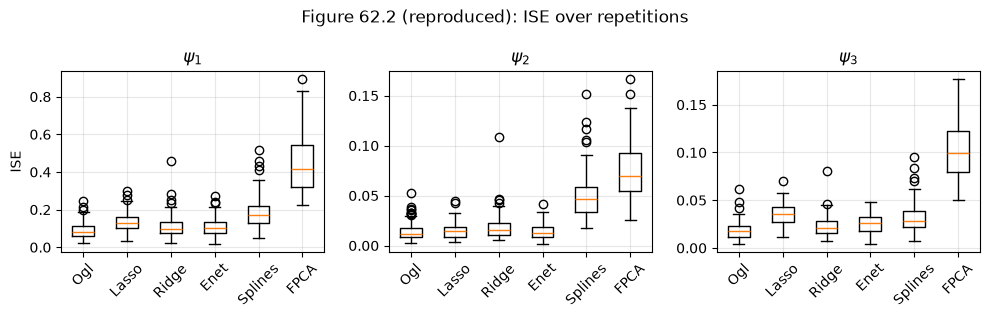

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
methods = ["Ogl", "Lasso", "Ridge", "Enet", "Splines", "FPCA"]
for ax, fn in zip(axes, ["psi1", "psi2", "psi3"]):
    ax.boxplot([results[fn][m]["ise"] for m in methods], tick_labels=methods)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("ISE")
axes[0].set_title(r"$\psi_1$")
axes[1].set_title(r"$\psi_2$")
axes[2].set_title(r"$\psi_3$")
plt.suptitle("Figure 62.2 (reproduced): ISE over repetitions")
plt.tight_layout()
plt.show()

Every method sees the same dataset on each repetition, so the comparison is paired: the
standard error of the *difference* is much smaller than that of either mean, and it is the one
that decides whether a gap is real.

In [7]:
n_rep = len(results["psi1"]["Ogl"]["ise"])
print(f"paired difference in ISE against the OGL, over {n_rep} repetitions\n")
print(f"{'fn':6}{'method':9}{'mean diff':>11}{'se':>9}{'t':>8}")
for fn in ["psi1", "psi2", "psi3"]:
    for m in methods[1:]:
        d = results[fn][m]["ise"] - results[fn]["Ogl"]["ise"]
        se = d.std(ddof=1) / np.sqrt(n_rep)
        print(f"{fn:6}{m:9}{d.mean():+11.4f}{se:9.4f}{d.mean() / se:8.2f}")

paired difference in ISE against the OGL, over 100 repetitions

fn    method     mean diff       se       t
psi1  Lasso        +0.0444   0.0044   10.03
psi1  Ridge        +0.0190   0.0045    4.25
psi1  Enet         +0.0194   0.0039    5.01
psi1  Splines      +0.0955   0.0075   12.82
psi1  FPCA         +0.3510   0.0157   22.35
psi2  Lasso        +0.0008   0.0007    1.19
psi2  Ridge        +0.0044   0.0011    3.90
psi2  Enet         +0.0005   0.0006    0.77
psi2  Splines      +0.0362   0.0022   16.42
psi2  FPCA         +0.0616   0.0029   21.22
psi3  Lasso        +0.0173   0.0011   16.36
psi3  Ridge        +0.0047   0.0005    8.92
psi3  Enet         +0.0073   0.0008    9.24
psi3  Splines      +0.0137   0.0012   11.45
psi3  FPCA         +0.0853   0.0031   27.15


We can see that the OGL beats every competitor on $\psi_1$ and $\psi_3$ by a wide margin. On
$\psi_2$ the picture is different: the gaps to Lasso and to Elastic Net are within one standard
error of zero, so on that function the overlap structure buys nothing over an ordinary Lasso on
the same design. That is the function whose support is a single interval in the middle of the
domain, where a plain Lasso can already switch off both tails, and where grouping adjacent
coefficients therefore has no structure left to exploit.

FPCA and Splines trail badly, and for different reasons: the spline fit on $W$ is unpenalised
altogether, while FPCA is regularised only through the number of components it retains, which
is a much blunter instrument than a penalty acting on the coefficient function itself.

The boxplots summarise ISE, but not the shape of the recovered curve. Here we fit the OGL at its own CV-selected lambda and plot it against the truth.

psi1, lambda = 0.00724, null_regions: []


psi2, lambda = 0.002235, null_regions: []


psi3, lambda = 0.003107, null_regions: []


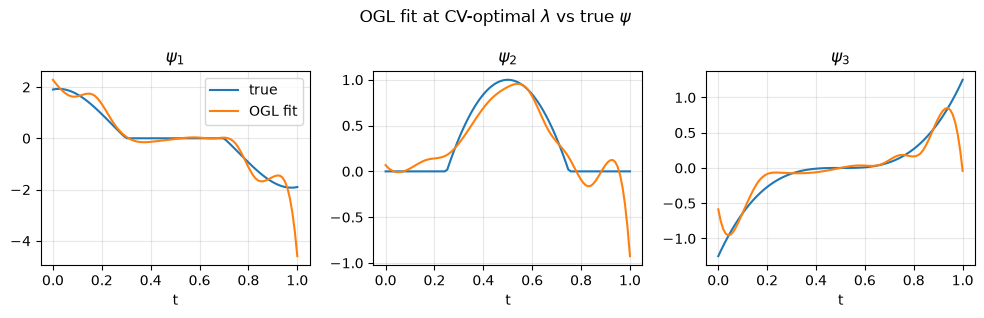

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, name in zip(axes, ["psi1", "psi2", "psi3"]):
    psi_fn, _ = SBC_sim.TRUE_FUNCTIONS[name]
    X, y, g, beta_true = SBC_sim.simulate(psi_fn, n=50, m=100)
    ogl = SBC.cv_fit(X, y, g, n_basis=15, n_folds=5, n_lambda=30)
    print(f"{name}, lambda = {ogl['lam_hat']:.4g}, null_regions: {ogl['null_regions']}")

    ax.plot(g, beta_true, label="true")
    ax.plot(g, ogl["beta"], label="OGL fit")
    for a, b in ogl["null_regions"]:
        ax.axvspan(a, b, color="red", alpha=0.15)
    ax.set_xlabel("t")
axes[0].legend()
axes[0].set_title(r"$\psi_1$")
axes[1].set_title(r"$\psi_2$")
axes[2].set_title(r"$\psi_3$")
plt.suptitle(r"OGL fit at CV-optimal $\lambda$ vs true $\psi$")
plt.tight_layout()
plt.show()

## Cross-validation does not deliver the sparsity

No null region is reported for any of the three functions, including $\psi_1$ and $\psi_2$
where one genuinely exists. This is the estimator's headline property and its own tuning rule
never produces it, so it is worth being precise about why.

Cross-validation targets prediction risk. A group of coefficients is worth keeping under that
criterion as soon as the squared bias it removes exceeds the variance it adds, however slim
the margin. Zeroing it *exactly* is worth strictly more than that for support recovery, so
the $\lambda$ that recovers $T_0$ is systematically larger than the $\lambda$ that predicts
best, and the gap does not close as $n$ grows. We can see the size of it directly by tracking
both criteria along the same path.

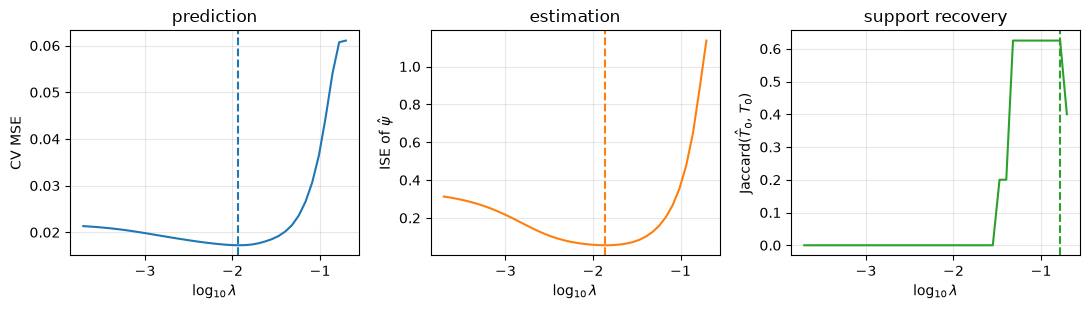

lambda minimising CV MSE        : 0.01161
lambda minimising ISE           : 0.01386
lambda maximising null-set match: 0.1655
best achievable Jaccard on this path: 0.625
Jaccard at the CV-selected lambda  : 0.000


In [9]:
X, y, g, beta_true = SBC_sim.simulate(SBC_sim.psi1, n=50, m=100, rng=7)
T0 = (g >= 0.3) & (g <= 0.7)

cv = SBC.cv_fit(X, y, g, n_basis=15, n_folds=5, n_lambda=40)
path = SBC.fit_path(X, y, g, lambdas=cv["lambdas"], n_basis=15)

ise_path = np.array([SBC_sim.ise(b, beta_true, g) for b in path["betas"]])
# Jaccard agreement between the estimated null set and the true one.
jacc = np.array([
    (s & T0).sum() / max((s | T0).sum(), 1) for s in ~path["supports"]
])

lam = path["lambdas"]
j_cv = int(np.argmin(cv["cv_mean"]))
j_ise = int(np.argmin(ise_path))
j_sup = int(np.argmax(jacc))

fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].plot(np.log10(lam), cv["cv_mean"], color="C0")
ax[0].axvline(np.log10(lam[j_cv]), color="C0", ls="--")
ax[0].set_ylabel("CV MSE"); ax[0].set_title("prediction")
ax[1].plot(np.log10(lam), ise_path, color="C1")
ax[1].axvline(np.log10(lam[j_ise]), color="C1", ls="--")
ax[1].set_ylabel(r"ISE of $\hat\psi$"); ax[1].set_title("estimation")
ax[2].plot(np.log10(lam), jacc, color="C2")
ax[2].axvline(np.log10(lam[j_sup]), color="C2", ls="--")
ax[2].set_ylabel(r"Jaccard($\hat T_0$, $T_0$)"); ax[2].set_title("support recovery")
for a in ax:
    a.set_xlabel(r"$\log_{10}\lambda$")
plt.tight_layout(); plt.show()

print(f"lambda minimising CV MSE        : {lam[j_cv]:.4g}")
print(f"lambda minimising ISE           : {lam[j_ise]:.4g}")
print(f"lambda maximising null-set match: {lam[j_sup]:.4g}")
print(f"best achievable Jaccard on this path: {jacc.max():.3f}")
print(f"Jaccard at the CV-selected lambda  : {jacc[j_cv]:.3f}")

The three optima sit at different places on the path, and they sit in a definite order: the
$\lambda$ that recovers the null set is the largest, the one that minimises ISE is next, and
the CV minimum is the smallest of the three. At the CV choice the recovered null set is empty,
while a $\lambda$ an order of magnitude larger recovers most of the true one and zeroes nothing
outside it.

So the practical rule is to report sparsity from a $\lambda$ chosen for support recovery and
to say so, rather than from the CV minimum. The path itself is the honest object: it shows
which regions switch off first and how stable they are, without committing to one penalty.
`tecator_application.ipynb` makes the same point on real data, where the null region the
paper reports sits some eight standard errors past the cross-validated minimum and neither
selection rule reaches it.